# Phase 2: polar-sector task setup



## 1. Setup: s2-spawn-randomization branch

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import os, shutil, subprocess, json, glob
DRIVE_ROOT = "/content/drive/MyDrive/spirob_vision"
OUT   = f"{DRIVE_ROOT}/polar_task"
WS    = f"{DRIVE_ROOT}/workspace_map"                 # Phase 1 results (background map)
CKPT  = f"{DRIVE_ROOT}/sir_stage1/model_499.pt"
REPO  = "/content/spirob-polar"                       # separate folder from the Stage-1 checkout
BRANCH = "origin/research/s2-spawn-randomization"
os.makedirs(OUT, exist_ok=True)
if shutil.which("uv") is None:
    subprocess.run("curl -LsSf https://astral.sh/uv/install.sh | sh", shell=True, check=True)
    os.environ["PATH"] = f"/root/.local/bin:{os.environ['PATH']}"
if not os.path.isdir(REPO):
    subprocess.run(["git", "clone", "https://github.com/YADlin/spirob-mjlab", REPO], check=True)
os.chdir(REPO)
subprocess.run(["git", "fetch", "origin"], check=True)
subprocess.run(["git", "checkout", "-B", "polar-work", BRANCH], check=True)
subprocess.run(["uv", "sync"], check=True)
print(subprocess.run(["uv", "run", "python", "-c",
    "import torch; from importlib.metadata import version as v; print('GPU:', torch.cuda.get_device_name(0)); "
    "print('mjlab', v('mjlab'), '| mujoco', v('mujoco'))"], capture_output=True, text=True).stdout)
print("checkpoint present:", os.path.isfile(CKPT), "| workspace map present:", os.path.isfile(f"{WS}/hold.npz"))

## 2. Write our polar tasks and the check script

In [ ]:
%%writefile /content/spirob-polar/tools/polar_tasks.py

from mjlab.managers.event_manager import EventTermCfg
from mjlab.managers.metrics_manager import MetricsTermCfg
from mjlab.tasks.registry import register_mjlab_task

import spirob_mjlab  # noqa: F401  (registers sir's tasks)
from spirob_mjlab import mdp
from spirob_mjlab.entities import movable_pedestal_cfg
from spirob_mjlab.env_cfgs import spirob_egg_to_bucket_stage1_env_cfg
from spirob_mjlab.rl_cfg import Stage2FineTuneRunner, spirob_ppo_runner_cfg

RADIUS_M = (0.120, 0.200)
POLAR_TASKS = {
    "Mjlab-SpiRob-Polar-Right": (RADIUS_M, (30.0, 80.0)),
    "Mjlab-SpiRob-Polar-Left": (RADIUS_M, (100.0, 150.0)),
    "Mjlab-SpiRob-Polar-Wide": (RADIUS_M, (30.0, 150.0)),
}


def polar_env_cfg(radius_range_m, angle_range_deg, play=False):
    cfg = spirob_egg_to_bucket_stage1_env_cfg(play=play)
    if play:
        cfg.episode_length_s = 8.0
    cfg.scene.entities["pedestal"] = movable_pedestal_cfg()
    cfg.events["stage2_egg_pedestal_spawn"] = EventTermCfg(
        func=mdp.reset_stage2_sector_egg_and_pedestal,
        mode="reset",
        params={
            "radius_range_m": radius_range_m,
            "angle_range_deg": angle_range_deg,
            # 1 x 1 strata: a wide sector crosses the robot/bucket exclusion zones,
            # and fully-excluded strata would make stratified sampling fail
            "radial_strata": 1,
            "angular_strata": 1,
            "schedule_length": 10,
            "nominal_slots": 1,
            "retention_slots": 3,
            "max_resample_attempts": 256,
            "min_robot_centerline_clearance": 0.038,
            "min_bucket_center_clearance": 0.055,
        },
    )
    cfg.metrics = {
        "spawn_radius_mm": MetricsTermCfg(func=mdp.stage2_spawn_radius_mm, reduce="last"),
        "spawn_angle_deg": MetricsTermCfg(func=mdp.stage2_spawn_angle_deg, reduce="last"),
        "spawn_is_sector": MetricsTermCfg(func=mdp.stage2_spawn_is_sector, reduce="last"),
        "spawn_rejection_count": MetricsTermCfg(func=mdp.stage2_spawn_rejection_count, reduce="last"),
    }
    return cfg


for _task_id, (_r, _th) in POLAR_TASKS.items():
    register_mjlab_task(
        task_id=_task_id,
        env_cfg=polar_env_cfg(_r, _th, play=False),
        play_env_cfg=polar_env_cfg(_r, _th, play=True),
        rl_cfg=spirob_ppo_runner_cfg(stage2=True),
        runner_cls=Stage2FineTuneRunner,
    )

In [ ]:
%%writefile /content/spirob-polar/tools/polar_check.py

import sys, os, json, time, argparse, math
from dataclasses import asdict
sys.path.insert(0, "/content/spirob-polar/tools")
import numpy as np
import torch
from tensordict import TensorDict
import polar_tasks  # noqa: F401  (registers the polar tasks)
from mjlab.envs import ManagerBasedRlEnv
from mjlab.rl import MjlabOnPolicyRunner, RslRlVecEnvWrapper
from mjlab.tasks.registry import load_env_cfg, load_rl_cfg, load_runner_cls

ap = argparse.ArgumentParser()
ap.add_argument("--mode", choices=["spawns", "eval"], required=True)
ap.add_argument("--task", default="Mjlab-SpiRob-Polar-Wide")
ap.add_argument("--out", required=True)
ap.add_argument("--ws", default="", help="workspace_map folder, for the background map")
ap.add_argument("--num_envs", type=int, default=512)
ap.add_argument("--rounds", type=int, default=3)
ap.add_argument("--checkpoint", default="")
ap.add_argument("--label", default="policy")
a = ap.parse_args()
os.makedirs(a.out, exist_ok=True)
DEV = "cuda:0"
BUCKET = (-0.05, 0.15)
GROUP = {0: "nominal", 1: "retention", 2: "sector"}


def make_env():
    cfg = load_env_cfg(a.task, play=False)
    cfg.scene.num_envs = a.num_envs
    cfg.auto_reset = False
    cfg.seed = 1001
    cfg.observations["actor"].enable_corruption = False
    cfg.observations["critic"].enable_corruption = False
    env = ManagerBasedRlEnv(cfg=cfg, device=DEV)
    vec = RslRlVecEnvWrapper(env, clip_actions=load_rl_cfg(a.task).clip_actions)
    return env, vec


def spawn_info(env):
    egg = env.scene["egg"].data.root_link_pos_w - env.scene.env_origins
    grp = getattr(env, "_stage2_spawn_group", torch.full((env.num_envs,), -1, device=DEV))
    return egg[:, :2].clone(), egg[:, 2].clone(), grp.clone()


def flags(env):
    tm = env.termination_manager
    g = lambda n: tm.get_term(n).bool()
    return g("success_egg_inside_bucket"), g("egg_fell") | g("egg_oob"), g("nan_state")


def run_round(env, vec, policy, steps):
    """One synchronous batch: every env runs one episode; finished envs are reset and masked."""
    vec.reset()
    xy, z0, grp = spawn_info(env)

    obs = TensorDict(env.observation_manager.compute(update_history=True), batch_size=[env.num_envs])
    N = env.num_envs
    done = torch.zeros(N, dtype=torch.bool, device=DEV)
    succ, fell, crash = done.clone(), done.clone(), done.clone()
    min_z = z0.clone()
    for t in range(steps):
        with torch.no_grad():
            act = policy(obs) if policy is not None else torch.zeros((N, 2), device=DEV)
        obs, _, dones, _ = vec.step(act)
        ez = env.scene["egg"].data.root_link_pos_w[:, 2]
        min_z = torch.where(done, min_z, torch.minimum(min_z, ez))
        s, f, n = flags(env)
        new = ~done & (s | f | n)
        succ |= new & s; fell |= new & f & ~s; crash |= new & n & ~s
        done |= new
        if bool(done.all()):
            break
        ended = torch.nonzero(dones.bool()).flatten()
        if len(ended):
            env.reset(env_ids=ended)
    return dict(xy=xy.cpu().numpy(), z0=z0.cpu().numpy(), group=grp.cpu().numpy(),
                success=succ.cpu().numpy(), fell=fell.cpu().numpy(), crash=crash.cpu().numpy(),
                drop_mm=((z0 - min_z) * 1000).cpu().numpy())


def background(ax):
    import matplotlib.pyplot as plt
    LIM, CELL = 0.35, 0.005
    NC = int(round(2 * LIM / CELL))
    grid = np.zeros(NC * NC)
    for f in ("hold.npz", "random.npz"):
        p = os.path.join(a.ws, f)
        if a.ws and os.path.isfile(p):
            grid += np.load(p)["body"]
    if grid.any():
        ax.imshow(np.log1p(grid.reshape(NC, NC)), origin="lower", extent=[-LIM, LIM, -LIM, LIM],
                  cmap="Greys", alpha=0.6)
    for rr in (0.12, 0.20):
        ax.add_patch(plt.Circle((0, 0), rr, fill=False, ls="--", lw=0.8, color="tab:blue"))
    ax.add_patch(plt.Circle(BUCKET, 0.055, fill=False, lw=1, color="red"))
    ax.axvspan(-0.038, 0.038, color="orange", alpha=0.12)
    ax.plot(*BUCKET, "s", color="red", label="bucket (+55 mm exclusion)")
    ax.plot(0, 0, "k+", ms=10, label="robot base")
    ax.set_xlim(-0.25, 0.25); ax.set_ylim(-0.02, 0.26); ax.set_aspect("equal")
    ax.set_xlabel("x (m)"); ax.set_ylabel("y (m)")


def polar(xy):
    return np.hypot(xy[:, 0], xy[:, 1]) * 1000, np.degrees(np.arctan2(xy[:, 1], xy[:, 0]))


import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

if a.mode == "spawns":
    env, vec = make_env()
    rows = [run_round(env, vec, None, 150) for _ in range(a.rounds)]   # robot held still, 1.5 s
    R = {k: np.concatenate([r[k] for r in rows]) for k in rows[0]}
    r_mm, th = polar(R["xy"])
    stable = (~R["fell"]) & (~R["crash"]) & (R["drop_mm"] < 5)
    print(f"{a.task}: {len(r_mm)} spawns")
    for g, name in GROUP.items():
        m = R["group"] == g
        if m.any():
            print(f"  {name:9s}: {m.sum():5d} spawns | r {r_mm[m].min():5.0f}-{r_mm[m].max():5.0f} mm | "
                  f"theta {th[m].min():5.1f}-{th[m].max():5.1f} deg | egg stays on pedestal {stable[m].mean():.0%}")
    bd = np.hypot(R["xy"][:, 0] - BUCKET[0], R["xy"][:, 1] - BUCKET[1]) * 1000
    print(f"  closest spawn to bucket centre: {bd.min():.0f} mm (must be >= 55) | "
          f"closest to robot centreline: {np.abs(R['xy'][:, 0]).min() * 1000:.0f} mm (must be >= 38)")
    print(f"  ALL spawns stable: {bool(stable.all())}  ({(~stable).sum()} unstable)")
    fig, ax = plt.subplots(figsize=(8, 5))
    background(ax)
    ax.scatter(R["xy"][stable, 0], R["xy"][stable, 1], s=4, c="tab:green", label="spawn, egg stays")
    if (~stable).any():
        ax.scatter(R["xy"][~stable, 0], R["xy"][~stable, 1], s=12, c="tab:red", marker="x", label="egg fell / crash")
    ax.set_title(f"{a.task}: spawns over the workspace map"); ax.legend(fontsize=7, loc="upper left")
    plt.tight_layout(); f = f"{a.out}/spawns_{a.task.split('-')[-1]}.png"; plt.savefig(f, dpi=130)
    print("saved", f)

else:  # eval
    assert a.checkpoint and os.path.isfile(a.checkpoint), "give --checkpoint"
    env, vec = make_env()
    agent_cfg = load_rl_cfg(a.task)
    runner_cls = load_runner_cls(a.task) or MjlabOnPolicyRunner
    runner = runner_cls(vec, asdict(agent_cfg), device=DEV)
    runner.load(a.checkpoint, load_cfg={"actor": True}, strict=True, map_location=DEV)
    policy = runner.get_inference_policy(device=DEV)
    T = int(env.max_episode_length) + 1
    rows = []
    for i in range(a.rounds):
        t0 = time.time()
        rows.append(run_round(env, vec, policy, T))
        print(f"round {i + 1}/{a.rounds}: {time.time() - t0:.0f}s, success {rows[-1]['success'].mean():.0%}", flush=True)
    R = {k: np.concatenate([r[k] for r in rows]) for k in rows[0]}
    r_mm, th = polar(R["xy"])
    out = {"task": a.task, "checkpoint": a.checkpoint, "label": a.label, "groups": {}, "by_angle": []}
    print(f"\n{a.label} on {a.task}")
    for g, name in GROUP.items():
        m = R["group"] == g
        if m.any():
            out["groups"][name] = {"n": int(m.sum()), "success": float(R["success"][m].mean()),
                                   "fell": float(R["fell"][m].mean())}
            print(f"  {name:9s}: success {R['success'][m].mean():5.0%}  fell {R['fell'][m].mean():5.0%}  (n={m.sum()})")
    sec = R["group"] == 2
    print("\n  sector spawns by angle:\n  theta (deg) |   n  | success | fell")
    for lo in range(30, 150, 10):
        m = sec & (th >= lo) & (th < lo + 10)
        if m.any():
            out["by_angle"].append({"theta": lo, "n": int(m.sum()), "success": float(R["success"][m].mean()),
                                    "fell": float(R["fell"][m].mean())})
            print(f"   {lo:3d}-{lo + 10:3d}   | {m.sum():4d} | {R['success'][m].mean():6.0%}  | {R['fell'][m].mean():4.0%}")
    json.dump(out, open(f"{a.out}/eval_{a.label}_{a.task.split('-')[-1]}.json", "w"), indent=1)
    np.savez(f"{a.out}/eval_{a.label}_{a.task.split('-')[-1]}.npz", **R)
    fig, ax = plt.subplots(figsize=(8, 5))
    background(ax)
    col = np.where(R["success"], "tab:green", np.where(R["fell"], "tab:red", "tab:gray"))
    ax.scatter(R["xy"][:, 0], R["xy"][:, 1], s=5, c=col)
    ax.set_title(f"{a.label} on {a.task}: green = success, red = fell, grey = timeout")
    plt.tight_layout(); f = f"{a.out}/eval_{a.label}_{a.task.split('-')[-1]}.png"; plt.savefig(f, dpi=130)
    print("saved", f)

In [ ]:
!python -m py_compile /content/spirob-polar/tools/polar_tasks.py /content/spirob-polar/tools/polar_check.py && echo "OK - no syntax errors"
!cd {REPO} && uv run python -c "import sys; sys.path.insert(0,'tools'); import polar_tasks; print('registered:', list(polar_tasks.POLAR_TASKS))"

## 3. Spawn check

   CUDA Toolkit 12.9, Driver 13.0
   Devices:
     "cpu"      : "x86_64"
     "cuda:0"   : "Tesla T4" (15 GiB, sm_75, mempool enabled)
   Kernel cache:
     /root/.cache/warp/1.14.0
Mjlab-SpiRob-Polar-Right: 1536 spawns
  nominal  :   153 spawns | r   158-  158 mm | theta  71.6- 71.6 deg | egg stays on pedestal 100%
  retention:   464 spawns | r   148-  170 mm | theta  68.3- 72.3 deg | egg stays on pedestal 100%
  sector   :   919 spawns | r   120-  200 mm | theta  30.0- 78.7 deg | egg stays on pedestal 100%
  closest spawn to bucket centre: 88 mm (must be >= 55) | closest to robot centreline: 38 mm (must be >= 38)
  ALL spawns stable: True  (0 unstable)
saved /content/drive/MyDrive/spirob_vision/polar_task/spawns_Right.png
------------------------------------------------------------
   CUDA Toolkit 12.9, Driver 13.0
   Devices:
     "cpu"      : "x86_64"
     "cuda:0"   : "Tesla T4" (15 GiB, sm_75, mempool enabled)
   Kernel cache:
     /root/.cache/warp/1.14.0
Mjlab-SpiRob-Polar-Left

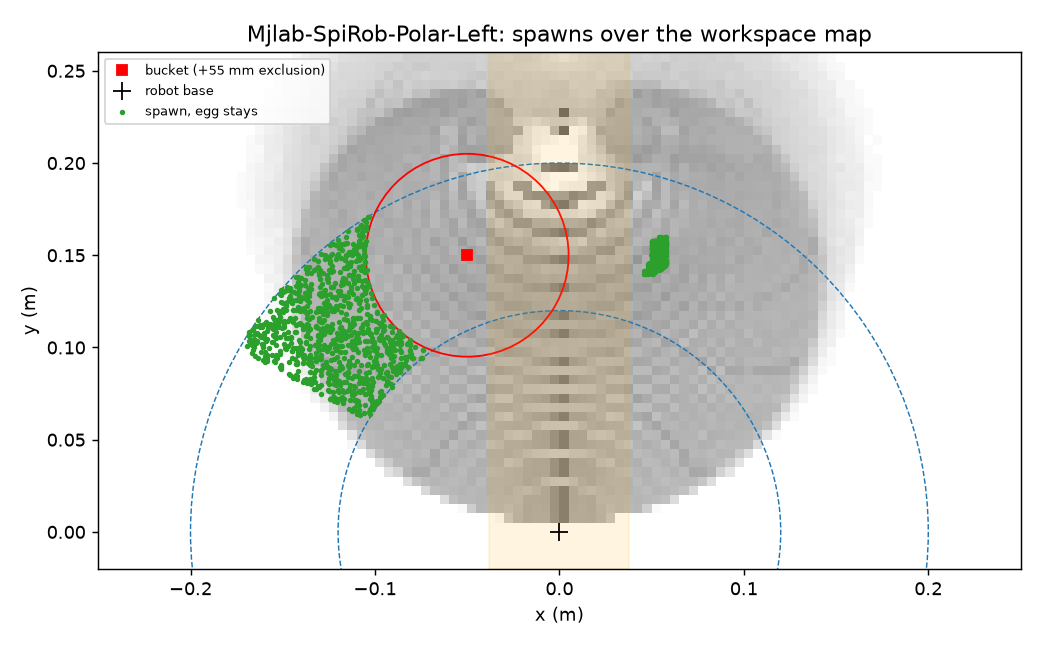

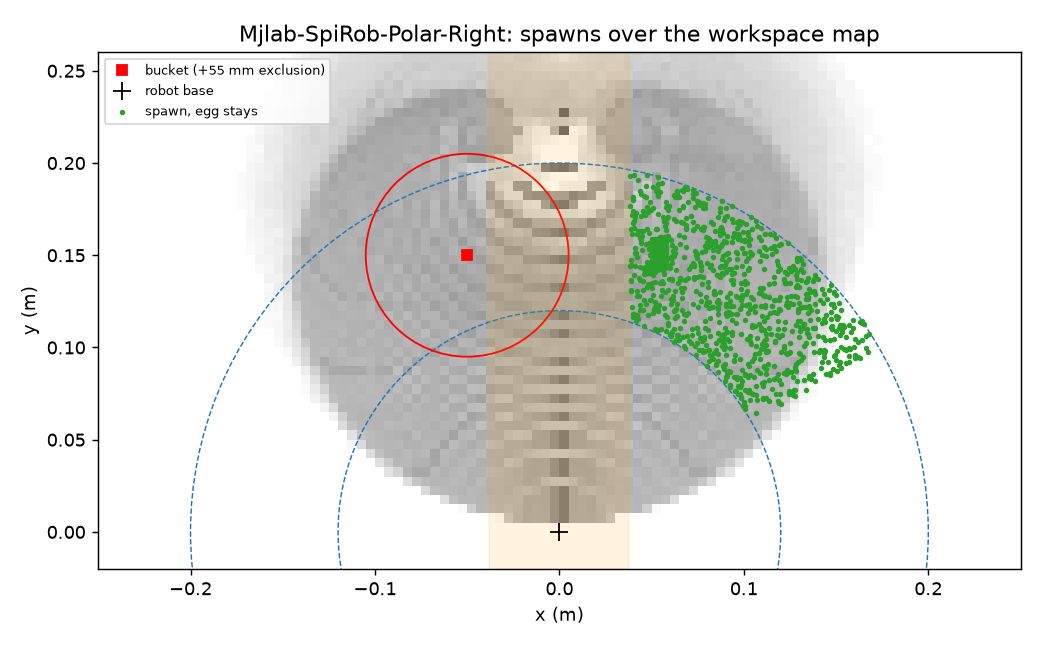

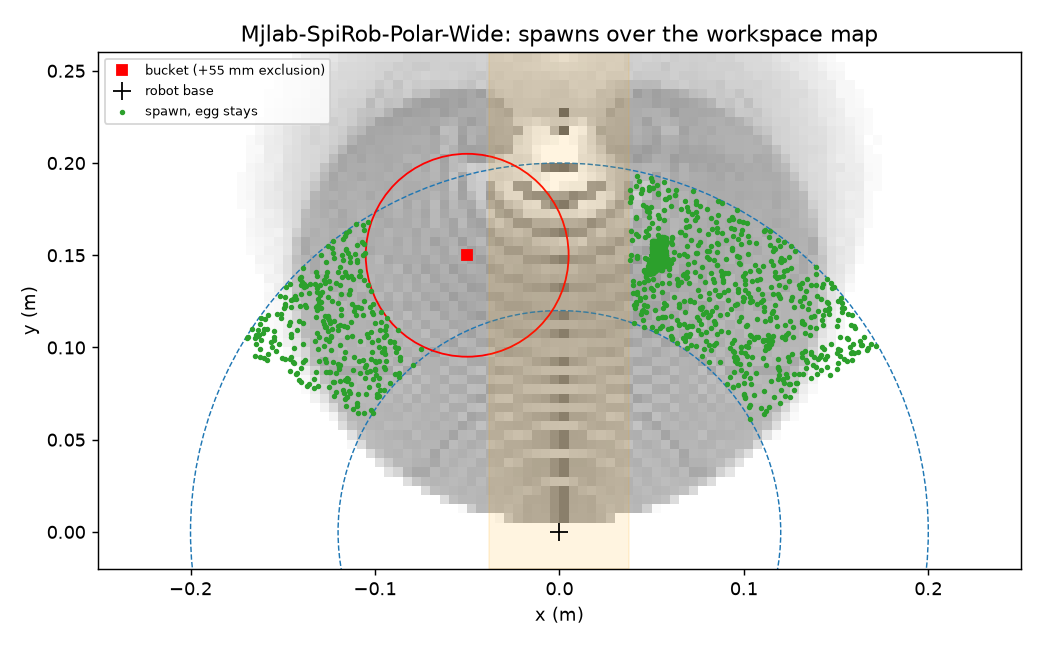

In [ ]:
for task in ("Mjlab-SpiRob-Polar-Right", "Mjlab-SpiRob-Polar-Left", "Mjlab-SpiRob-Polar-Wide"):
    r = subprocess.run(["uv", "run", "python", "tools/polar_check.py", "--mode", "spawns", "--task", task,
                        "--out", OUT, "--ws", WS, "--num_envs", "512", "--rounds", "3"],
                       cwd=REPO, capture_output=True, text=True)
    lines = [l for l in (r.stdout + r.stderr).splitlines()
             if l.startswith(("Mjlab", "  ", "saved")) or "Error" in l or "Traceback" in l]
    print("\n".join(lines[-15:])); print("-" * 60)
from IPython.display import Image, display
for f in sorted(glob.glob(f"{OUT}/spawns_*.png")):
    display(Image(f, width=750))

## 4. Check checkpoint loads

In [ ]:
!cd {REPO} && uv run python -c "import torch; ck=torch.load('{CKPT}', map_location='cpu', weights_only=False); print('iter', ck.get('iter'), '| keys', list(ck)); print({{k: tuple(v.shape) for k, v in ck['actor_state_dict'].items() if 'weight' in k}})"

## 5. Baseline: model_499 across the polar sector

Setting seed: 1001
Warp 1.14.0 initialized:
   CUDA Toolkit 12.9, Driver 13.0
   Devices:
     "cpu"      : "x86_64"
     "cuda:0"   : "Tesla T4" (15 GiB, sm_75, mempool enabled)
   Kernel cache:
     /root/.cache/warp/1.14.0
Module mujoco_warp._src.smooth cf7a289 load on device 'cuda:0' took 3.54 ms  (cached)
Module mujoco_warp._src.collision_driver 621a3f9 load on device 'cuda:0' took 0.55 ms  (cached)
Module _nxn_broadphase__locals__kernel_4ee3649d 4ee3649 load on device 'cuda:0' took 0.55 ms  (cached)
Module ccd_kernel_builder__locals__ccd_kernel_c1aa383f c1aa383 load on device 'cuda:0' took 2.21 ms  (cached)
Module ccd_kernel_builder__locals__ccd_kernel_85133f97 85133f9 load on device 'cuda:0' took 1.63 ms  (cached)
Module ccd_kernel_builder__locals__ccd_kernel_15a19499 15a1949 load on device 'cuda:0' took 1.67 ms  (cached)
Module ccd_kernel_builder__locals__ccd_kernel_713b615b 713b615 load on device 'cuda:0' took 2.30 ms  (cached)
Module _primitive_narrowphase__locals__primitive_

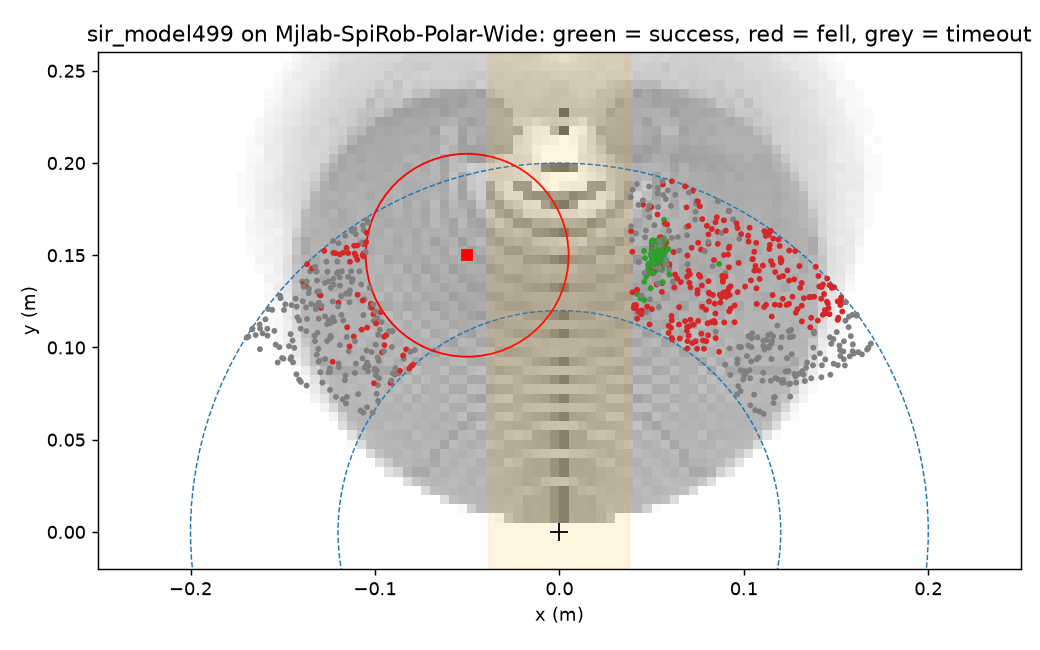

In [ ]:
!cd {REPO} && uv run python tools/polar_check.py --mode eval --task Mjlab-SpiRob-Polar-Wide --checkpoint "{CKPT}" --label sir_model499 --out "{OUT}" --ws "{WS}" --num_envs 512 --rounds 2
display(Image(f"{OUT}/eval_sir_model499_Wide.png", width=750))